# 03 · Point labels from reference routes + candidate generation (train + student_test)
`.route` is an ordered list of arc ids, not one label per GPS point. Each point is assigned to a route arc with a
monotonic dynamic programme (route order never goes backwards, total point-to-arc distance minimised).

In [1]:
import sys, os
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pathsnap").is_dir()), None)
if _root is None:
    raise RuntimeError("src/pathsnap not found: unzip all zips of the set into the same pathsnap/ folder")
sys.path.insert(0, str(_root / "src")); os.chdir(_root / "notebooks")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathsnap import io, labels, candidates

FIG = "../outputs/figures"

In [2]:
rows, store = [], {}
for split in ["train", "student_test"]:
    for tid in io.list_trips(split):
        tr = io.load_trip(split, tid)
        lab, ld = labels.align_route(tr)
        C, D, _ = candidates.generate(tr, k=16, radius=300)
        store[(split, tid)] = (lab, ld, C, D)
        rows.append(dict(split=split, trip=tid, n=len(lab), label_dist_med=np.median(ld),
                         label_dist_p95=np.percentile(ld, 95), frac_over_50m=np.mean(ld > 50),
                         nearest_arc_acc=np.mean(C[:, 0] == lab)))
lq = pd.DataFrame(rows)
lq["reliable"] = lq.frac_over_50m < 0.2
lq.to_csv("../outputs/label_quality.csv", index=False)
lq.sort_values("label_dist_med", ascending=False).head(6)

,split,trip,n,label_dist_med,label_dist_p95,frac_over_50m,nearest_arc_acc,reliable
44,train,00000054,19313,140.008729,209.605772,0.894423,0.069073,False
26,train,00000033,5844,122.383217,142.022479,0.588638,0.187029,False
35,train,00000043,2322,10.998763,70.033951,0.071059,0.510767,True
3,train,00000004,1064,8.503561,29.475580,0.000000,0.449248,True
6,train,00000008,3093,7.788118,28.162410,0.006790,0.363401,True
63,train,00000080,2510,7.385931,28.403984,0.000398,0.723108,True


              label_dist_med  nearest_arc_acc
split                                        
student_test           5.083            0.575
train                  8.155            0.562
unreliable trips: ['00000033', '00000054']


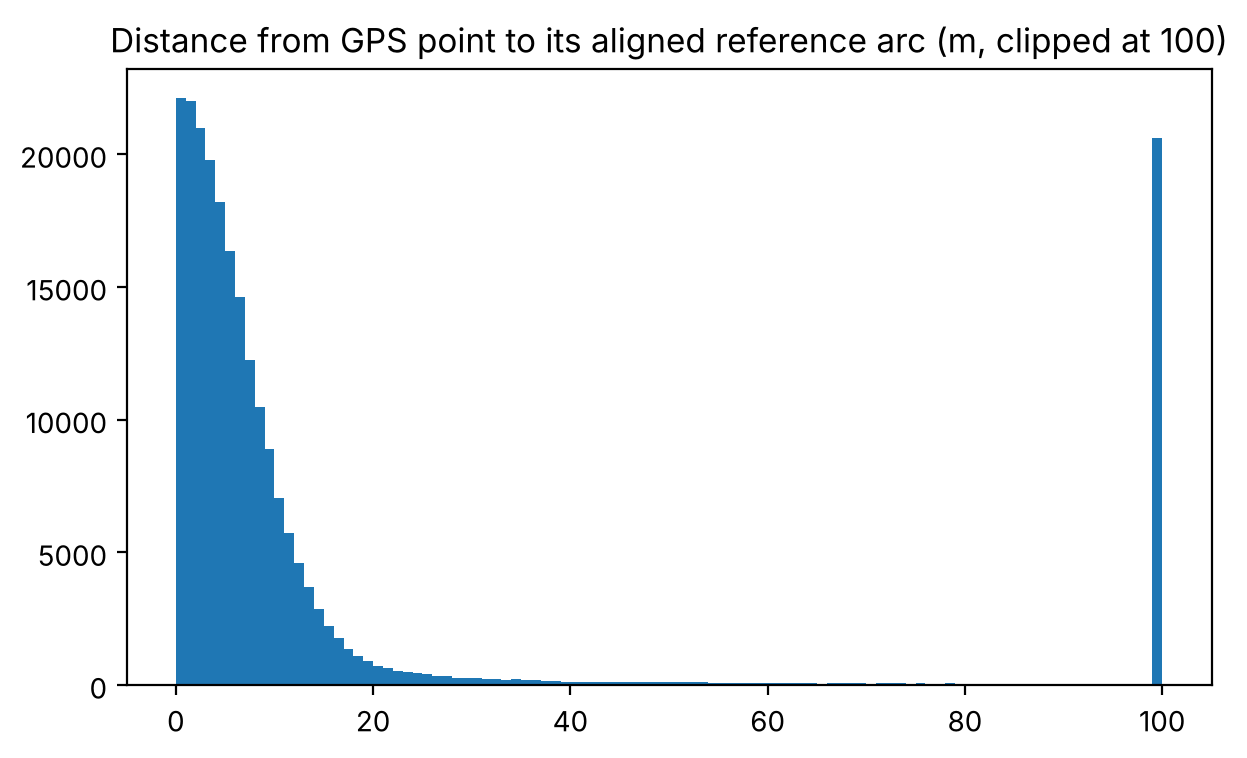

In [3]:
all_ld = np.concatenate([v[1] for v in store.values()])
plt.figure(figsize=(7, 4))
plt.hist(np.minimum(all_ld, 100), bins=100)
plt.title("Distance from GPS point to its aligned reference arc (m, clipped at 100)")
plt.savefig(f"{FIG}/label_distance.png", dpi=120)
print(lq.groupby("split")[["label_dist_med", "nearest_arc_acc"]].mean().round(3))
print("unreliable trips:", lq[~lq.reliable].trip.tolist())

Candidate miss rate (reference arc not in the candidate set) vs K and search radius, reliable train trips only

In [4]:
def miss(K, R, split="train"):
    hit, tot = 0, 0
    for (s, tid), (lab, ld, C, D) in store.items():
        if s != split or not lq.set_index("trip").loc[tid, "reliable"]:
            continue
        ok = ((C[:, :K] == lab[:, None]) & (D[:, :K] <= R)).any(1)
        hit += ok.sum(); tot += len(ok)
    return 1 - hit / tot

grid = pd.DataFrame([dict(K=k, radius=r, miss_rate=miss(k, r)) for k in [2, 4, 6, 8, 12, 16] for r in [30, 50, 100, 200]])
grid.to_csv("../outputs/candidate_grid.csv", index=False)
grid.pivot(index="K", columns="radius", values="miss_rate").round(4)

radius,30,50,100,200
K,,,,
2,0.0955,0.0886,0.0829,0.0823
4,0.0459,0.0377,0.0316,0.0310
6,0.0322,0.0234,0.0170,0.0163
8,0.0280,0.0185,0.0119,0.0112
12,0.0257,0.0157,0.0088,0.0079
16,0.0250,0.0149,0.0078,0.0069


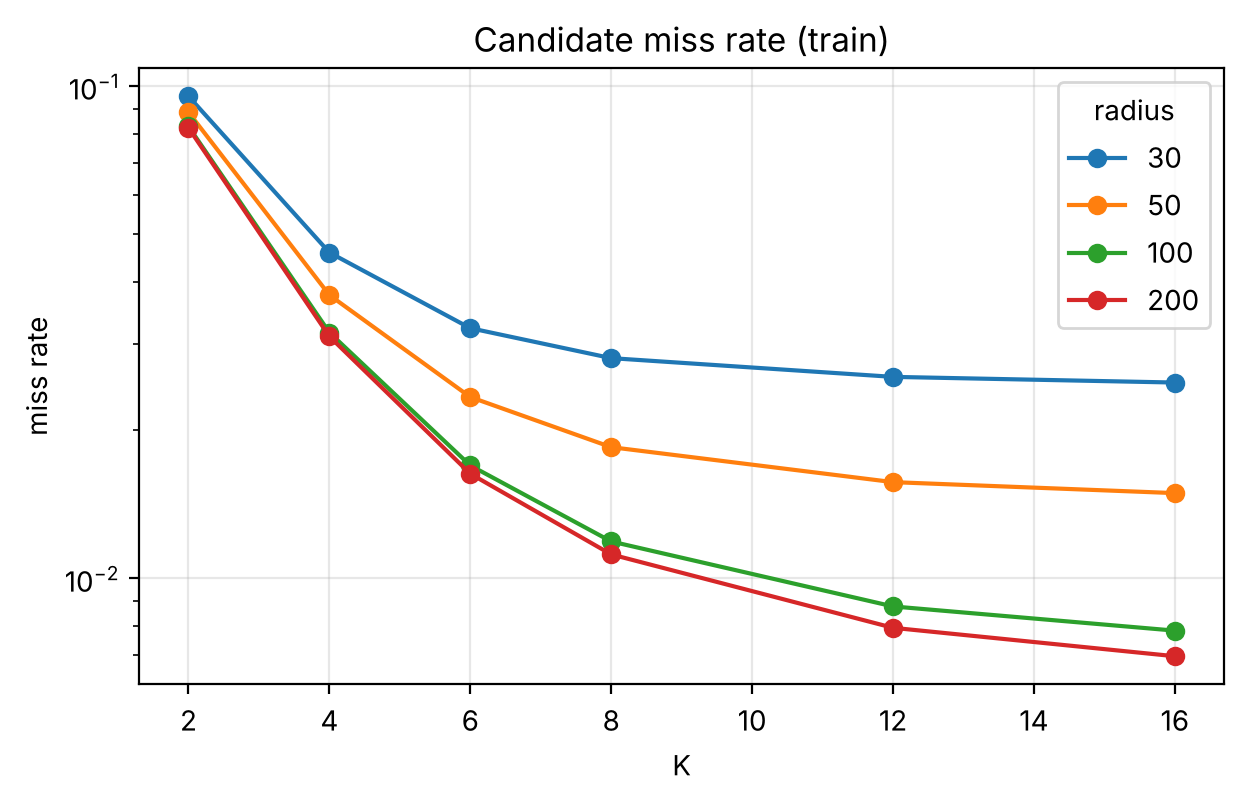

In [5]:
piv = grid.pivot(index="K", columns="radius", values="miss_rate")
piv.plot(marker="o", figsize=(7, 4), logy=True, title="Candidate miss rate (train)")
plt.ylabel("miss rate"); plt.grid(alpha=.3); plt.savefig(f"{FIG}/candidate_miss_rate.png", dpi=120)

In [6]:
print("chosen K=8, radius=100 m | train miss:", round(miss(8, 100), 4), "| student_test miss:", round(miss(8, 100, "student_test"), 4))

chosen K=8, radius=100 m | train miss: 0.0119 | student_test miss: 0.0037
